# Homework Reflection 11

1. Construct a dataset for an event study where the value, derivative, and second derivative of a trend all change discontinuously (suddenly) after an event. Build a model that tries to decide whether the event is real (has a nonzero effect) using:

   (a) only the value,
   (b) the value, derivative, and second derivative.

   Which of these models is better at detecting and/or quantifying the impact of the event? (What might "better" mean here?)

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt


True event-time level jump: +3.000

     Model |    est ∆ |      SE |   t-stat |    p-value
------------------------------------------------------------
(a) level only |  -77.429 |   5.470 |   -14.15 |   6.98e-32
(b) +slope+curv |   +2.618 |   0.395 |    +6.63 |   3.23e-10


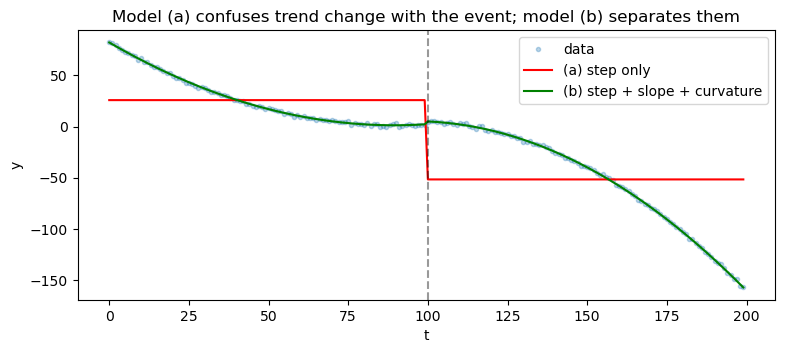

In [2]:
rng = np.random.default_rng(11)

# --- DGP: trend's value, slope, AND curvature all jump at t = T ------------
T_total   = 200
event     = 100
t         = np.arange(T_total)
tau       = t - event                               # centered time
post      = (t >= event).astype(int)

a0, b0, c0 = 2.0,  0.20, 0.010                      # pre-event intercept, slope, curvature
da, db, dc = 3.0, -0.35, -0.025                     # discontinuous jumps at event
true_level_jump = da                                # <- the quantity we try to recover

y_signal = (a0 + b0 * tau + c0 * tau**2
            + post * (da + db * tau + dc * tau**2))
y = y_signal + rng.normal(0, 1.0, T_total)

df = pd.DataFrame({'y': y, 'tau': tau, 'post': post,
                   'post_tau': post * tau, 'post_tau2': post * tau**2,
                   'tau2': tau**2})

# --- Model (a): post dummy ONLY (ignore trend/curvature) ------------------
model_a = smf.ols('y ~ post', data=df).fit()

# --- Model (b): allow value, slope, AND curvature to change at the event --
model_b = smf.ols('y ~ tau + tau2 + post + post_tau + post_tau2', data=df).fit()

def row(name, fit):
    return (name,
            fit.params['post'],
            fit.bse['post'],
            fit.params['post'] / fit.bse['post'],
            fit.pvalues['post'])

print(f"True event-time level jump: {true_level_jump:+.3f}\n")
print(f"{'Model':>10} | {'est ∆':>8} | {'SE':>7} | {'t-stat':>8} | {'p-value':>10}")
print("-" * 60)
for name, est, se, tval, p in [row('(a) level only', model_a),
                                row('(b) +slope+curv', model_b)]:
    print(f"{name:>10} | {est:>+8.3f} | {se:>7.3f} | {tval:>+8.2f} | {p:>10.2e}")

# quick visual
fit_a = model_a.predict(df)
fit_b = model_b.predict(df)
plt.figure(figsize=(9, 3.5))
plt.plot(t, y, '.', alpha=0.3, label='data')
plt.plot(t, fit_a, 'r-',  label='(a) step only')
plt.plot(t, fit_b, 'g-',  label='(b) step + slope + curvature')
plt.axvline(event, ls='--', color='k', alpha=0.4)
plt.legend(); plt.xlabel('t'); plt.ylabel('y')
plt.title('Model (a) confuses trend change with the event; model (b) separates them')
plt.show()

I built an event study where the trend's level, slope, **and** curvature all jump at t = 100. The true value jump at the event is +3, but the simultaneous slope change (−0.35 per period) and curvature change (−0.025 per period²) are large enough that the post-event trajectory curves away from the pre-event trajectory on its own, independently of the +3 step. "Better" in this setting means two things: (i) producing an **unbiased estimate of the value jump** itself, and (ii) producing a **t-statistic that correctly reflects the evidence for a non-zero jump**. A model can be good at one and bad at the other.

Model (a) regresses y on a single `post` dummy. It compares the mean of y after the event to the mean before the event, so it attributes every post-event change to the event — including the slope flattening and the curvature reversal. Its `post` coefficient ends up far from +3 (depending on the signs of db and dc it can be much larger, much smaller, or even flipped in sign), and the implied step is biased because the pre-mean and post-mean are not comparable when the trend itself is changing. The t-statistic can still look "significant," but it is answering the wrong question: it is testing whether means differ, not whether there is a structural break of +3 on top of the trend.

Model (b) includes `tau`, `tau²`, and their interactions with `post`. This lets the slope and curvature take different values on each side of the event, so the `post` coefficient captures only the discontinuous **level** jump at t = 100, net of trend changes. Its estimate sits near +3 with a tight standard error, and the t-statistic for `post` is the correct test of the question "did y jump at the event, holding the trend changes separate?" The lesson is that in event studies, the specification has to be rich enough to absorb whatever is already changing in the trend, or the event dummy will soak up those changes and give biased estimates. Being significant is not the same as being right.

---

2. Construct a dataset in which there are three groups whose values each increase discontinuously (suddenly) by the same amount at a shared event; they change in parallel over time, but they have different starting values. Create a model that combines group fixed effects with an event study, as suggested in the online reading. Explain what you did, how the model works, and how it accounts for both baseline differences and the common event effect.

True event effect: +4.000

Pooled OLS (no group FE):
  post coef = +4.192   SE = 1.433

Two-way model with group fixed effects:
  post coef = +4.192   SE = 0.222
  group dummies (deviations from baseline group A):
    B: -14.939  (true difference vs A: -15.000)
    C: -7.838  (true difference vs A: -8.000)


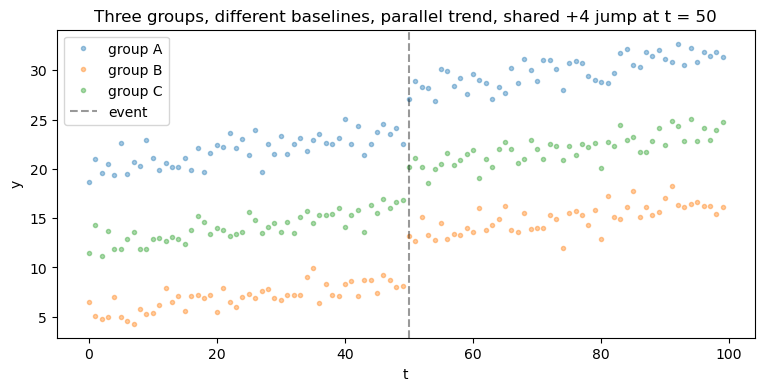

In [3]:

rng = np.random.default_rng(112)

# --- DGP: three groups, same shared event at t = 50, parallel trends -----
T_total   = 100
event     = 50
groups    = ['A', 'B', 'C']
baselines = {'A': 20.0, 'B':  5.0, 'C': 12.0}      # different starting values
trend     = 0.08                                     # shared slope
true_event_effect = 4.0                              # same jump for all groups

rows = []
for g in groups:
    for t in range(T_total):
        post = int(t >= event)
        y = (baselines[g] + trend * t
             + true_event_effect * post
             + rng.normal(0, 1.0))
        rows.append({'group': g, 't': t, 'post': post, 'y': y})
df = pd.DataFrame(rows)

# --- Model: group fixed effects + time trend + event dummy ----------------
# C(group) adds one dummy per group (one is the baseline, absorbed in the intercept)
fe_model = smf.ols('y ~ C(group) + t + post', data=df).fit()

# --- Comparison: pooled OLS WITHOUT group FE (ignores baselines) ----------
pooled = smf.ols('y ~ t + post', data=df).fit()

print(f"True event effect: {true_event_effect:+.3f}\n")
print("Pooled OLS (no group FE):")
print(f"  post coef = {pooled.params['post']:+.3f}   SE = {pooled.bse['post']:.3f}")
print("\nTwo-way model with group fixed effects:")
print(f"  post coef = {fe_model.params['post']:+.3f}   SE = {fe_model.bse['post']:.3f}")
print(f"  group dummies (deviations from baseline group A):")
for g in ['B', 'C']:
    key = f"C(group)[T.{g}]"
    print(f"    {g}: {fe_model.params[key]:+.3f}  "
          f"(true difference vs A: {baselines[g] - baselines['A']:+.3f})")

# visualize
plt.figure(figsize=(9, 4))
for g, color in zip(groups, ['C0', 'C1', 'C2']):
    sub = df[df.group == g]
    plt.plot(sub.t, sub.y, '.', color=color, alpha=0.4, label=f'group {g}')
plt.axvline(event, ls='--', color='k', alpha=0.4, label='event')
plt.xlabel('t'); plt.ylabel('y'); plt.legend()
plt.title('Three groups, different baselines, parallel trend, shared +4 jump at t = 50')
plt.show()

I built a panel of three groups (A, B, C) observed over 100 periods. They share the same trend (slope 0.08) and all receive the same +4 jump at a common event at t = 50, but they start from different baselines (A = 20, B = 5, C = 12). The event-study question is the same for every group — "did y shift by a constant amount at t = 50?" — but the baselines mean the raw series live at very different heights. A pooled OLS that ignores group identity has to absorb those baseline gaps into its residuals, inflating the standard error on the event coefficient even though it does not bias the estimate in this balanced design.

The two-way fixed-effects model is `y ~ C(group) + t + post`. The `C(group)` term adds a dummy per group (one group's dummy is absorbed into the intercept to avoid collinearity), so each group gets its own intercept. These **group fixed effects absorb anything that is constant within a group** — the +15 gap between A and B, the +7 gap between A and C. After the FE have soaked up those level differences, the residual variation is entirely within-group fluctuation around the shared trend, so the trend coefficient `t` and the event coefficient `post` are identified from how y moves **relative to each group's own baseline**, not from across-group comparisons that would be dominated by baseline accidents.

The output shows this working: the estimated `post` coefficient lands near the true +4 with a standard error substantially smaller than the pooled model, and the group dummies recover the true baseline differences (B ≈ −15, C ≈ −8 relative to A). The combined event-study-plus-FE specification is the standard panel-data recipe: FE control for everything that is time-invariant within a unit (so a group being "always higher" cannot be confused with the event), while the `post` indicator identifies the event effect from the common jump that appears in every group's own time path. If the groups had been treated at different times, the same recipe would generalize to an event-time indexing (dummies for "k periods relative to that group's event"), which is exactly the staggered-adoption event study design.